# Weekly project

Today you are going to implement the last parts of the algorithm you started on monday. For reference you can see it below.

![title](algorithm_3.png)

It is a good idea to follow and track the steps in the algorithm in the below implementation. Only take one step at a time.

Once you have the algorithm up and running you can try with a larger dataset to see if your algorithm is able to maintain good accurracy over a longer distance. The larger dataset can be found here:
[Left images](https://dtudk-my.sharepoint.com/:u:/g/personal/evanb_dtu_dk/EQu8kmGBDDROtGJ7IkZB2tQBJrxmgY9t8LVM_JuEi83TYw)
[Right images](https://dtudk-my.sharepoint.com/:u:/g/personal/evanb_dtu_dk/EcKI_zrXTvpMulizidCZm4oBLJcQ_LTV9Zs6oQFF74JTRQ)

In [1]:
import numpy as np
import cv2 as cv2
import glob

def getK():
    return np.array([[7.188560e+02, 0.000000e+00, 6.071928e+02],
                     [0, 7.188560e+02, 1.852157e+02],
                     [0, 0, 1]])

def getTruePose():
    file = 'left/00.txt'
    return np.genfromtxt(file, delimiter=' ', dtype=None)

<details>
  <summary>tips:</summary>

- [Feature Matching](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html)
- To get the keypoint of a certain match do: ```kp1[match.queryIdx].pt``` and ```kp2[match.trainIdx].pt```

### `extract_keypoints_sift` (steps 1.2 and 1.3)

- **SIFT:** `detectAndCompute` finds keypoints in each image and computes a 128-D descriptor for each one.
- **Matching:** `knnMatch(k=2)` finds the two closest descriptors in the other image for every keypoint.
- **Lowe's ratio test:** a match is kept only if the best match is clearly better than the second best (`m.distance < 0.75 * n.distance`). This removes ambiguous matches.
- For each kept match, `kp1[m.queryIdx].pt` and `kp2[m.trainIdx].pt` give the pixel coordinates in the two images. These matched points are then triangulated into 3D.

In [2]:
def extract_keypoints_sift(img1, img2, K, baseline):
    """
    Use SIFT to detect keypoints and compute descriptors in both images,
    and find matches between them using knnMatch with k=2
    """
    sift = cv2.SIFT_create()
    kp1, des1 = sift.detectAndCompute(img1,None)
    kp2, des2 = sift.detectAndCompute(img2,None)

    """
    Get the best keypoints by applying the Lowes ratio test
    """
    bf = cv2.BFMatcher()
    matches = bf.knnMatch(des1,des2,k=2)
 

    match_points1 = []
    match_points2 = []
    for pair in matches:
        if len(pair) < 2:
            continue
        m, n = pair
        if m.distance < 0.75 * n.distance:
            match_points1.append(kp1[m.queryIdx].pt)
            match_points2.append(kp2[m.trainIdx].pt)
            
    # Transform best keypoints to nparray
    p1 = np.array(match_points1).astype('float32')
    p2 = np.array(match_points2).astype('float32')
    

    ##### ############# ##########
    ##### Do Triangulation #######
    ##### ########################
    # project the feature points to 3D with triangulation
    # projection matrix for Left and Right Image
    M_left = K.dot(np.hstack((np.eye(3), np.zeros((3, 1)))))
    M_rght = K.dot(np.hstack((np.eye(3), np.array([[-baseline, 0, 0]]).T)))

    p1_flip = np.vstack((p1.T, np.ones((1, p1.shape[0]))))
    p2_flip = np.vstack((p2.T, np.ones((1, p2.shape[0]))))

    P = cv2.triangulatePoints(M_left, M_rght, p1_flip[:2], p2_flip[:2])

    # Normalize homogeneous coordinates (P->Nx4  [N,4] is the normalizer/scale)
    P = P / P[3]
    land_points = P[:3]

    return land_points.T, p1

### `featureTracking` (step 2.2)

- **KLT optical flow:** `cv2.calcOpticalFlowPyrLK` finds where each point from the previous frame (`prev_points`) moved to in the new frame, giving `next_points`.
- **Parameters:** `winSize=(21, 21)` sets the search window around each point, and `maxLevel=3` sets the number of image pyramid levels, so the tracker can handle larger motion.
- **Filtering:** points that could not be tracked (`status == 0`) are removed from `world_points`, `prev_points` and `next_points` with the same mask. This keeps the 3D-to-2D pairs lined up for PnP in step 2.3.

In [3]:
def featureTracking(prev_img, next_img, prev_points, world_points):
    """
    Use OpenCV to find the prev_points from the prev_img in the next_img
    Remember to remove points that could not be found from prev_points, next_points, and world_points
    hint: status == 1
    """
    params = dict(winSize=(21, 21),
                 maxLevel=3,
                 criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))

    #next_points, status, _ = ...
    next_points, status, error = cv2.calcOpticalFlowPyrLK(prev_img, next_img, prev_points, None, **params)


    status = status.ravel() == 1
    world_points = world_points[status]
    prev_points = prev_points[status]
    next_points = next_points[status]

    

    return world_points, prev_points, next_points

### `playImageSequence` (the full VO loop)

- **Initialization (1.2–1.3):** `extract_keypoints_sift` on the first stereo pair gives the starting 3D landmarks (`landmark_3D`) and their 2D positions in the left image (`reference_2D`).
- **Tracking (2.2):** `featureTracking` follows `reference_2D` from the previous left image into the current one, giving `tracked_2D`.
- **Pose (2.3):** `cv2.solvePnPRansac` uses the 3D-to-2D pairs (`landmark_3D`, `tracked_2D`) to estimate the camera pose. The pose is then inverted to get the camera position in world coordinates.
- **New landmarks (2.4):** `extract_keypoints_sift` on the current stereo pair triangulates fresh points, which are transformed into world coordinates and used as the reference for the next frame.
- The estimated trajectory (red) is plotted against the ground truth (blue), and the maximum position error is reported.

In [ ]:
def playImageSequence(l_img_paths, r_img_paths, K):
    baseline = 0.54
    left_img = cv2.imread(l_img_paths[0], 0)
    right_img = cv2.imread(r_img_paths[0], 0)

    ##### ################################# #######
    ##### Get 3D points Using Triangulation #######
    ##### #########################################
    """
    Implement step 1.2 and 1.3
    Store the features in 'reference_2D' and the 3D points (landmarks) in 'landmark_3D'
    hint: use 'extract_keypoints_sift' above
    """

    
    landmark_3D, reference_2D= extract_keypoints_sift(left_img, right_img, K, baseline)


    # reference
    reference_img = left_img

    # Groundtruth for plot
    truePose = getTruePose()
    traj = np.zeros((600, 600, 3), dtype=np.uint8)
    maxError = 0

    for i in range(1, 1770):
        print('image: ', i)
        curImage = cv2.imread(l_img_paths[i], 0)
        curImage_R = cv2.imread(r_img_paths[i], 0)

        ##### ############################################################# #######
        ##### Calculate 2D and 3D feature correspndances in t=T-1, and t=T  #######
        ##### #####################################################################
        """
        Implement step 2.2)
        Remember this is a part of a loop, so the initial features are already
        provided in step 1)-1.3) outside the loop in 'reference_2D' and 'landmark_3D'
        """
        
        landmark_3D, reference_2D, tracked_2D = featureTracking(reference_img, curImage, reference_2D, landmark_3D)

        

        ##### ####################################### #######
        ##### Calculate relative pose using PNPRansac #######
        ##### ###############################################
        """
        Implement step 2.3)
        """
        _, rvec, tvec, inliers = cv2.solvePnPRansac(landmark_3D, tracked_2D, K, None)

        ##### ####################################################### #######
        ##### Get Pose and Tranformation Matrix in world coordionates #######
        ##### ###############################################################
        rot, _ = cv2.Rodrigues(rvec)
        tvec = -rot.T.dot(tvec)  # coordinate transformation, from camera to world. What is the XYZ of the camera wrt World
        inv_transform = np.hstack((rot.T, tvec))  # inverse transform. A tranform projecting points from the camera frame to the world frame

        ##### ################################# #######
        ##### Get 3D points Using Triangulation #######
        ##### #########################################
        # re-obtain the 3D points. 
        # hint: use 'extract_keypoints_sift' again
        """
        Implement step 2.4)
        """

        landmark_3D_new, reference_2D_new = extract_keypoints_sift(curImage, curImage_R, K, baseline)

        
        #Project the points from camera to world coordinates
        reference_2D = reference_2D_new.astype('float32')
        landmark_3D = inv_transform.dot(np.vstack((landmark_3D_new.T, np.ones((1, landmark_3D_new.shape[0])))))
        landmark_3D = landmark_3D.T

        ##### ####################### #######
        ##### Done, Next image please #######
        ##### ###############################
        reference_img = curImage

        ##### ################################## #######
        ##### START OF Print and visualize stuff #######
        ##### ##########################################
        # draw images
        draw_x, draw_y = int(tvec[0]) + 300, 600-(int(tvec[2]) + 100)
        true_x, true_y = int(truePose[i][3]) + 300, 600-(int(truePose[i][11]) + 100)

        curError = np.sqrt(
            (tvec[0] - truePose[i][3]) ** 2 +
            (tvec[1] - truePose[i][7]) ** 2 +
            (tvec[2] - truePose[i][11]) ** 2)
        
        if (curError > maxError):
            maxError = curError

        print(tvec[0],tvec[1],tvec[2], rvec[0], rvec[1], rvec[2])
        print([truePose[i][3], truePose[i][7], truePose[i][11]])
        
        text = "Coordinates: x ={0:02f}m y = {1:02f}m z = {2:02f}m".format(float(tvec[0]), float(tvec[1]),
                                                                           float(tvec[2]))
        cv2.circle(traj, (draw_x, draw_y), 1, (0, 0, 255), 2)
        cv2.circle(traj, (true_x, true_y), 1, (255, 0, 0), 2)
        cv2.rectangle(traj, (10, 30), (550, 50), (0, 0, 0), cv2.FILLED)
        cv2.putText(traj, text, (10, 50), cv2.FONT_HERSHEY_PLAIN, 1, (255, 255, 255), 1, 8)

        h1, w1 = traj.shape[:2]
        h2, w2 = curImage.shape[:2]
        vis = np.zeros((max(h1, h2), w1 + w2, 3), np.uint8)
        vis[:h1, :w1, :3] = traj
        vis[:h2, w1:w1 + w2, :3] = np.dstack((np.dstack((curImage,curImage)),curImage))

        cv2.imshow("Trajectory", vis)
        k = cv2.waitKey(1) & 0xFF
        if k == 27: break


    cv2.waitKey(0)
    cv2.destroyAllWindows()
    print('Maximum Error: ', maxError)
    ##### ################################ #######
    ##### END OF Print and visualize stuff #######
    ##### ########################################

In [42]:
# Load image paths
left_img_paths = sorted(glob.glob('left/*.png'))
right_img_paths = sorted(glob.glob('right/*.png'))

K = getK()

playImageSequence(left_img_paths, right_img_paths, K)

image:  1


C:\Users\skiel\AppData\Local\Temp\ipykernel_70200\1326085318.py:86: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  draw_x, draw_y = int(tvec[0]) + 300, 600-(int(tvec[2]) + 100)
C:\Users\skiel\AppData\Local\Temp\ipykernel_70200\1326085318.py:100: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  text = "Coordinates: x ={0:02f}m y = {1:02f}m z = {2:02f}m".format(float(tvec[0]), float(tvec[1]),
C:\Users\skiel\AppData\Local\Temp\ipykernel_70200\1326085318.py:101: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this op

[-0.00227639] [-0.00703883] [0.67547856] [-0.0021743] [0.0033434] [-0.00261038]
[np.float64(-0.04690294), np.float64(-0.02839928), np.float64(0.8586941)]
image:  2
[-0.01421141] [-0.01295006] [1.37229912] [-0.00388048] [0.00737936] [-0.00082553]
[np.float64(-0.09374345), np.float64(-0.05676064), np.float64(1.716275)]
image:  3
[-0.03120015] [-0.02015718] [2.08366941] [-0.00540023] [0.01121703] [-0.00063776]
[np.float64(-0.1406429), np.float64(-0.08515762), np.float64(2.574964)]
image:  4
[-0.04991079] [-0.03387802] [2.81420207] [-0.00587349] [0.01610271] [0.00107941]
[np.float64(-0.1874858), np.float64(-0.1135202), np.float64(3.432648)]
image:  5
[-0.06623033] [-0.04580846] [3.55701708] [-0.00606627] [0.02065917] [6.16501316e-05]
[np.float64(-0.2343818), np.float64(-0.141915), np.float64(4.291335)]
image:  6
[-0.09174803] [-0.05829526] [4.31238505] [-0.007368] [0.02521116] [0.00215092]
[np.float64(-0.2812195), np.float64(-0.1702743), np.float64(5.148987)]
image:  7
[-0.12515103] [-0.07

We see lots of drift... Lets try the challenge!

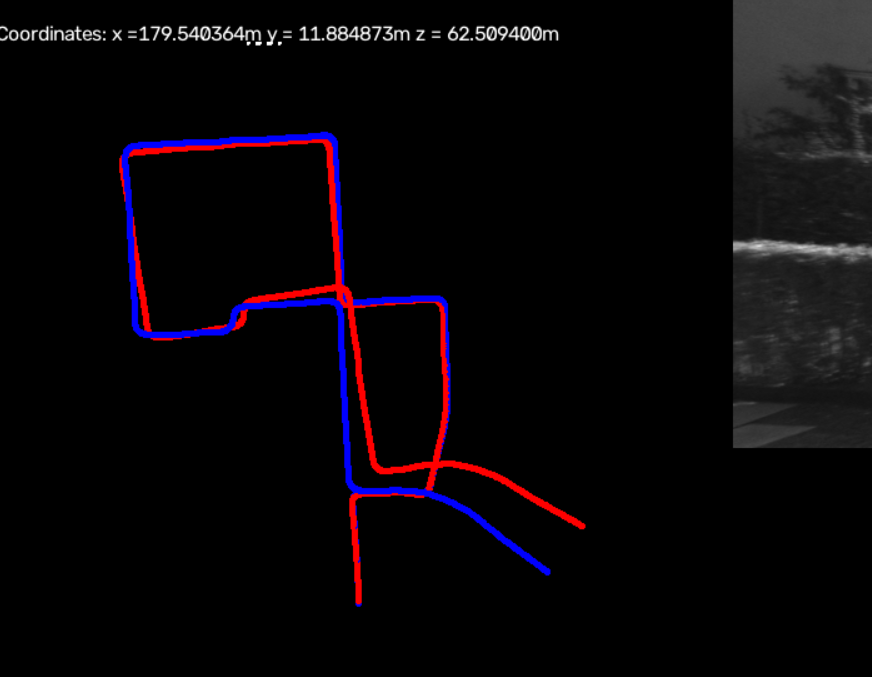

# Challenge 
The current implementation only uses features computed at the current timestep. However, as we process more images we potentially have a lot of features from previous timesteps that are still valid. The challenge is to expand the `extract_keypoints_surf(..., refPoints)` function by giving it old reference points. You should then combine your freshly computed features with the old features and remove all duplicates. This requires you to keep track of old features and 3D points.

Hint 1: The following function `removeDuplicate` can be used for removing duplicates.

Hint 2: you are not interested in points that are behind you, so remember to remove points that are negative in the direction you move.

In [4]:
def removeDuplicate(queryPoints, refPoints, radius=5):
    # remove duplicate points from new query points,
    for i in range(len(queryPoints)):
        query = queryPoints[i]
        xliml, xlimh = query[0] - radius, query[0] + radius
        yliml, ylimh = query[1] - radius, query[1] + radius
        inside_x_lim_mask = (refPoints[:, 0] > xliml) & (refPoints[:, 0] < xlimh)
        curr_kps_in_x_lim = refPoints[inside_x_lim_mask]

        if curr_kps_in_x_lim.shape[0] != 0:
            inside_y_lim_mask = (curr_kps_in_x_lim[:, 1] > yliml) & (curr_kps_in_x_lim[:, 1] < ylimh)
            curr_kps_in_x_lim_and_y_lim = curr_kps_in_x_lim[inside_y_lim_mask, :]
            if curr_kps_in_x_lim_and_y_lim.shape[0] != 0:
                queryPoints[i] = np.array([0, 0])
    return (queryPoints[:, 0] != 0)

### Challenge: changes to `extract_keypoints_sift`

- A new optional argument, `refPoints`, holds the old points that are still being tracked, at their positions in the current left image.
- After the ratio test, `removeDuplicate` returns a mask that is `False` for any new keypoint within 5 px of an old point. Both `p1` and `p2` are filtered with this mask, so the left-right pairs stay matched.
- `p1.copy()` is passed because `removeDuplicate` overwrites duplicates in its input array.
- On the first call (step 1.2) there are no old points yet, so `refPoints=None` skips the check.


In [5]:
def extract_keypoints_sift(img1, img2, K, baseline, refPoints=None):
    """
    Use SIFT to detect keypoints and compute descriptors in both images,
    and find matches between them using knnMatch with k=2
    """
    sift = cv2.SIFT_create()
    kp1, des1 = sift.detectAndCompute(img1,None)
    kp2, des2 = sift.detectAndCompute(img2,None)

    """
    Get the best keypoints by applying the Lowes ratio test
    """
    bf = cv2.BFMatcher()
    matches = bf.knnMatch(des1,des2,k=2)
 

    match_points1 = []
    match_points2 = []
    for pair in matches:
        if len(pair) < 2:
            continue
        m, n = pair
        if m.distance < 0.75 * n.distance:
            match_points1.append(kp1[m.queryIdx].pt)
            match_points2.append(kp2[m.trainIdx].pt)
            
    # Transform best keypoints to nparray
    p1 = np.array(match_points1).astype('float32')
    p2 = np.array(match_points2).astype('float32')

    if refPoints is not None and len(refPoints) > 0:
        keep = removeDuplicate(p1.copy(), refPoints)
        p1, p2 = p1[keep], p2[keep]
    

    ##### ############# ##########
    ##### Do Triangulation #######
    ##### ########################
    # project the feature points to 3D with triangulation
    # projection matrix for Left and Right Image
    M_left = K.dot(np.hstack((np.eye(3), np.zeros((3, 1)))))
    M_rght = K.dot(np.hstack((np.eye(3), np.array([[-baseline, 0, 0]]).T)))

    p1_flip = np.vstack((p1.T, np.ones((1, p1.shape[0]))))
    p2_flip = np.vstack((p2.T, np.ones((1, p2.shape[0]))))

    P = cv2.triangulatePoints(M_left, M_rght, p1_flip[:2], p2_flip[:2])

    # Normalize homogeneous coordinates (P->Nx4  [N,4] is the normalizer/scale)
    P = P / P[3]
    land_points = P[:3]

    return land_points.T, p1

### Challenge: changes to the image loop (step 2.4)

- The tracked points (`tracked_2D`) are passed as `refPoints`, so only **new, non-duplicate** features are triangulated.
- The new 3D points are in the **current camera frame**, so `inv_transform` = $[R^T \mid -R^T t]$ converts them to world coordinates (`new_3D_world`), the same frame as the old landmarks.
- The old and new points are then **stacked**, old first and new second, in both the 2D and the 3D arrays. This keeps row *i* of `reference_2D` paired with row *i* of `landmark_3D`.
- `tracked_2D` is used for the old 2D points because those are their positions in `curImage`, which is the reference image for the next iteration.


In [6]:
def playImageSequence(l_img_paths, r_img_paths, K):
    baseline = 0.54
    left_img = cv2.imread(l_img_paths[0], 0)
    right_img = cv2.imread(r_img_paths[0], 0)

    ##### ################################# #######
    ##### Get 3D points Using Triangulation #######
    ##### #########################################
    """
    Implement step 1.2 and 1.3
    Store the features in 'reference_2D' and the 3D points (landmarks) in 'landmark_3D'
    hint: use 'extract_keypoints_sift' above
    """

    
    landmark_3D, reference_2D= extract_keypoints_sift(left_img, right_img, K, baseline)


    # reference
    reference_img = left_img

    # Groundtruth for plot
    truePose = getTruePose()
    traj = np.zeros((600, 600, 3), dtype=np.uint8)
    maxError = 0

    for i in range(1, 1770):
        print('image: ', i)
        curImage = cv2.imread(l_img_paths[i], 0)
        curImage_R = cv2.imread(r_img_paths[i], 0)

        ##### ############################################################# #######
        ##### Calculate 2D and 3D feature correspndances in t=T-1, and t=T  #######
        ##### #####################################################################
        """
        Implement step 2.2)
        Remember this is a part of a loop, so the initial features are already
        provided in step 1)-1.3) outside the loop in 'reference_2D' and 'landmark_3D'
        """
        
        landmark_3D, reference_2D, tracked_2D = featureTracking(reference_img, curImage, reference_2D, landmark_3D)
        

        ##### ####################################### #######
        ##### Calculate relative pose using PNPRansac #######
        ##### ###############################################
        """
        Implement step 2.3)
        """
        _, rvec, tvec, inliers = cv2.solvePnPRansac(landmark_3D, tracked_2D, K, None)

        ##### ####################################################### #######
        ##### Get Pose and Tranformation Matrix in world coordionates #######
        ##### ###############################################################
        rot, _ = cv2.Rodrigues(rvec)
        tvec = -rot.T.dot(tvec)  # coordinate transformation, from camera to world. What is the XYZ of the camera wrt World
        inv_transform = np.hstack((rot.T, tvec))  # inverse transform. A tranform projecting points from the camera frame to the world frame

        ##### ################################# #######
        ##### Get 3D points Using Triangulation #######
        ##### #########################################
        # re-obtain the 3D points. 
        # hint: use 'extract_keypoints_sift' again
        """
        Implement step 2.4)
        """

        landmark_3D_new, reference_2D_new = extract_keypoints_sift(curImage, curImage_R, K, baseline, tracked_2D)

        ones = np.ones((1, landmark_3D_new.shape[0]))
        new_3D_world = inv_transform.dot(np.vstack((landmark_3D_new.T, ones))).T

        reference_2D = np.vstack((tracked_2D.reshape(-1, 2), reference_2D_new)).astype('float32')
        landmark_3D  = np.vstack((landmark_3D, new_3D_world))

        ##### ####################### #######
        ##### Done, Next image please #######
        ##### ###############################
        reference_img = curImage

        ##### ################################## #######
        ##### START OF Print and visualize stuff #######
        ##### ##########################################
        # draw images
        draw_x, draw_y = int(tvec[0]) + 300, 600-(int(tvec[2]) + 100)
        true_x, true_y = int(truePose[i][3]) + 300, 600-(int(truePose[i][11]) + 100)

        curError = np.sqrt(
            (tvec[0] - truePose[i][3]) ** 2 +
            (tvec[1] - truePose[i][7]) ** 2 +
            (tvec[2] - truePose[i][11]) ** 2)
        
        if (curError > maxError):
            maxError = curError

        print(tvec[0],tvec[1],tvec[2], rvec[0], rvec[1], rvec[2])
        print([truePose[i][3], truePose[i][7], truePose[i][11]])
        
        text = "Coordinates: x ={0:02f}m y = {1:02f}m z = {2:02f}m".format(float(tvec[0]), float(tvec[1]),
                                                                           float(tvec[2]))
        cv2.circle(traj, (draw_x, draw_y), 1, (0, 0, 255), 2)
        cv2.circle(traj, (true_x, true_y), 1, (255, 0, 0), 2)
        cv2.rectangle(traj, (10, 30), (550, 50), (0, 0, 0), cv2.FILLED)
        cv2.putText(traj, text, (10, 50), cv2.FONT_HERSHEY_PLAIN, 1, (255, 255, 255), 1, 8)

        h1, w1 = traj.shape[:2]
        h2, w2 = curImage.shape[:2]
        vis = np.zeros((max(h1, h2), w1 + w2, 3), np.uint8)
        vis[:h1, :w1, :3] = traj
        vis[:h2, w1:w1 + w2, :3] = np.dstack((np.dstack((curImage,curImage)),curImage))

        cv2.imshow("Trajectory", vis)
        k = cv2.waitKey(1) & 0xFF
        if k == 27: break


    cv2.waitKey(0)
    cv2.destroyAllWindows()
    print('Maximum Error: ', maxError)
    ##### ################################ #######
    ##### END OF Print and visualize stuff #######
    ##### ########################################

In [8]:
# Load image paths
left_img_paths = sorted(glob.glob('left/*.png'))
right_img_paths = sorted(glob.glob('right/*.png'))

K = getK()

playImageSequence(left_img_paths, right_img_paths, K)

image:  1
[-0.00227639] [-0.00703883] [0.67547856] [-0.0021743] [0.0033434] [-0.00261038]
[np.float64(-0.04690294), np.float64(-0.02839928), np.float64(0.8586941)]


C:\Users\skiel\AppData\Local\Temp\ipykernel_61172\1426225888.py:85: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  draw_x, draw_y = int(tvec[0]) + 300, 600-(int(tvec[2]) + 100)
C:\Users\skiel\AppData\Local\Temp\ipykernel_61172\1426225888.py:99: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  text = "Coordinates: x ={0:02f}m y = {1:02f}m z = {2:02f}m".format(float(tvec[0]), float(tvec[1]),
C:\Users\skiel\AppData\Local\Temp\ipykernel_61172\1426225888.py:100: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this ope

image:  2
[-0.01270739] [-0.01251486] [1.3762355] [-0.0037557] [0.0075534] [-0.00104958]
[np.float64(-0.09374345), np.float64(-0.05676064), np.float64(1.716275)]
image:  3
[-0.03007626] [-0.0177261] [2.09017952] [-0.00522282] [0.01151808] [-0.00097248]
[np.float64(-0.1406429), np.float64(-0.08515762), np.float64(2.574964)]
image:  4
[-0.04932098] [-0.02500541] [2.82446906] [-0.00586537] [0.0164125] [0.00032512]
[np.float64(-0.1874858), np.float64(-0.1135202), np.float64(3.432648)]
image:  5
[-0.07036669] [-0.03361227] [3.56540028] [-0.00613662] [0.02081502] [-0.00066796]
[np.float64(-0.2343818), np.float64(-0.141915), np.float64(4.291335)]
image:  6
[-0.0949433] [-0.05272118] [4.32147226] [-0.00705131] [0.02546055] [0.00134607]
[np.float64(-0.2812195), np.float64(-0.1702743), np.float64(5.148987)]
image:  7
[-0.13206895] [-0.05397042] [5.08809199] [-0.00799649] [0.03023525] [0.00414154]
[np.float64(-0.3281178), np.float64(-0.1986703), np.float64(6.007777)]
image:  8
[-0.16213583] [-0.0

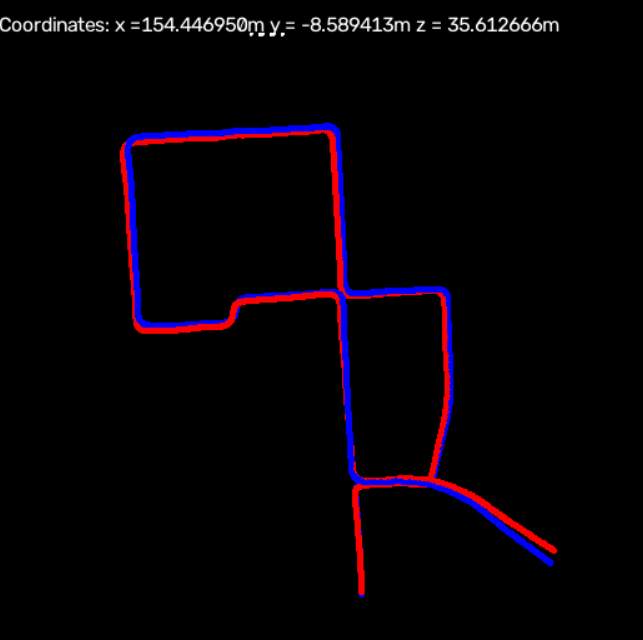

### Discussion: baseline vs. challenge

Both trajectories follow the ground truth's shape, but the baseline drifts more over time. Its second loop and final segment end up noticeably off. The baseline replaces all landmarks every frame, so new triangulation noise is added each time. In the challenge version, tracked landmarks are kept and only new, non-duplicate points are added. PnP therefore gets more and more stable correspondences, and the estimate stays much closer to the ground truth.


**AI disclaimer:** AI was used to assist and polish in writing of explanations, and explain some cv2 methods.